In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils import resample
from sklearn.base import clone
from pathlib import Path

# EX.A.1.: 1) Load the train and test datasets in pandas; 2) preprocess the text and
# vectorize each news article; 3) train a logistic regression model and two other
# ML algorithms to classify news in fake or true.
data_dir = Path("data")
if not data_dir.exists():
    data_dir = Path("assignment2") / "data"
Train = pd.read_csv(data_dir / "fake_news_train.csv")
Test  = pd.read_csv(data_dir / "fake_news_test.csv")

X_train = Train["title_text"].fillna("").astype(str)
X_test  = Test["title_text"].fillna("").astype(str)
y_train = Train["fake_news"].astype(int).values
y_test  = Test["fake_news"].astype(int).values
print(X_train.shape, X_test.shape)

(2000,) (300,)


In [2]:
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Cleaning from Lecture 14
URL_RE = re.compile(r'(?:https?://|www\.)\S+')

EXTRA_STOPS = {"http","https","httpps","www","com","net","org","co","amp","rt"}
STOPWORDS = ENGLISH_STOP_WORDS.union(EXTRA_STOPS)

def clean_text_simple(text):
    t = "" if text is None else str(text).lower()
    t = URL_RE.sub(" ", t)                 # kill URLs
    t = re.sub(r"[^a-z\s]", " ", t)        # keep letters + spaces
    t = re.sub(r"\s+", " ", t).strip()     # tidy spaces
    return t

def tokenize_simple(text):
    t = clean_text_simple(text)
    return [w for w in t.split() if w not in STOPWORDS and len(w) > 1]

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    analyzer = tokenize_simple,   # returns a list of tokens
    ngram_range = (1,1),
    min_df = 3,
    max_df = 0.85
)

Xtrain = tfidf.fit_transform(X_train)
Xtest = tfidf.transform(X_test)
vocab_size = len(tfidf.get_feature_names_out())
print(f"(A.1) Vocabulary size: {vocab_size}")
feature_names = tfidf.get_feature_names_out()

(A.1) Vocabulary size: 12058


## Model 1 - Logistic Regression

Acc: 0.963 | AUC: 0.987 | PR-AUC: 0.988


Text(0.5, 1.0, 'Logistic Regression')

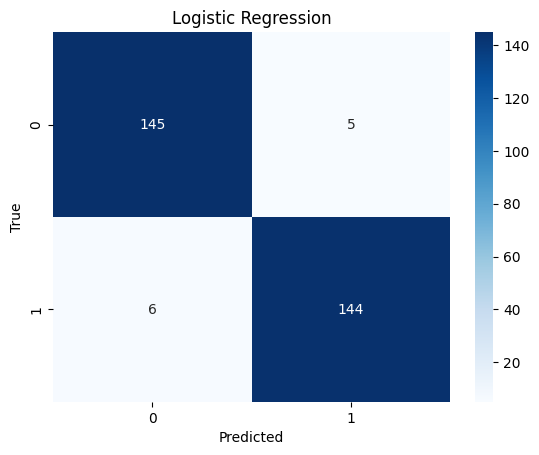

In [3]:
# EX.A.2.: for each model, report the relevant performance metrics (accuracy, ROC-AUC and 
# PR-AUC) and the training parameters (ML methods chosen like in 
# Lecture_13_supervised_machine_learning, so logistic regression,
# Random Forest and SVC).

# Logistic Regression
logit = LogisticRegression(max_iter = 2000, solver = 'liblinear')
logit.fit(Xtrain, y_train)

# predict probabilities 
proba_lr = logit.predict_proba(Xtest)[:,1]
# predict class 
pred_lr  = (proba_lr>=0.5).astype(int)

# compute metrics
print("Acc:", round(accuracy_score(y_test, pred_lr),3),
      "| AUC:", round(roc_auc_score(y_test, proba_lr),3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_lr),3))

# confusion matrix
sns.heatmap(confusion_matrix(y_test, pred_lr, normalize = None), annot = True,fmt = 'd', cmap = 'Blues')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.title('Logistic Regression')

## Model 2 - SVC (RBF)

Acc: 0.967 | AUC: 0.989 | PR-AUC: 0.989


Text(0.5, 1.0, 'Support Vector Machine')

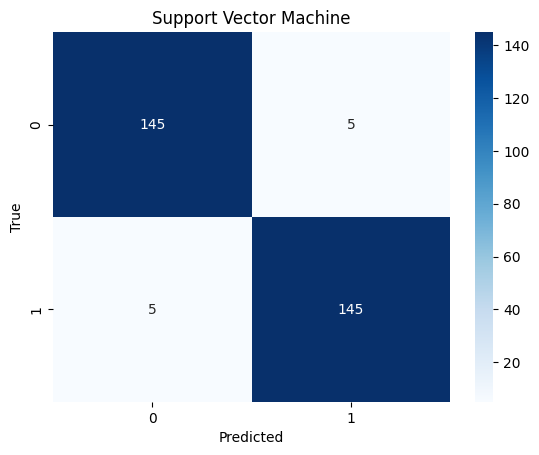

In [4]:
# SVC with RBF
svc = SVC(kernel = 'rbf', probability = True, C = 1.0, gamma = 'scale', random_state = 42)
svc.fit(Xtrain, y_train)

# predict probabilities
proba_svc = svc.predict_proba(Xtest)[:,1]
# predict class
pred_svc = (proba_svc>=0.5).astype(int)

# compute metrics
print("Acc:", round(accuracy_score(y_test, pred_svc),3),
      "| AUC:", round(roc_auc_score(y_test, proba_svc),3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_svc),3))

# confusion matrix
sns.heatmap(confusion_matrix(y_test, pred_svc, normalize = None), annot = True,fmt = 'd', cmap = 'Blues')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.title('Support Vector Machine')

## Model 3 - Random Forest (GridSearchCV)

Best: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 400} | CV AUC: 0.993
Acc: 0.96 | AUC: 0.993 | PR-AUC: 0.994


Text(0.5, 1.0, 'Random Forest')

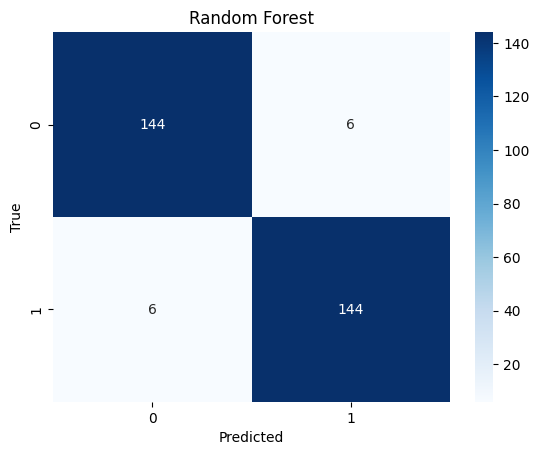

In [5]:
# Random Forest with GridSearchCV
rf = RandomForestClassifier(random_state = 42, n_jobs = -1)

# parameters to explore
param_grid_rf = {
    'n_estimators':[200,400],
    'max_depth':[None,8,12],
    'max_features':['sqrt',0.5],
    'min_samples_leaf':[1,3]
}

# grid search
gcv_rf = GridSearchCV(rf, param_grid_rf, scoring = 'roc_auc', cv = 3, n_jobs = -1)
gcv_rf.fit(Xtrain, y_train)

# save best model
rf_best = gcv_rf.best_estimator_

# predict probabilities
proba_rf = rf_best.predict_proba(Xtest)[:,1]
# predict class
pred_rf = (proba_rf>=0.5).astype(int)

# compute metrics
print("Best:", gcv_rf.best_params_, "| CV AUC:", round(gcv_rf.best_score_,3))
print("Acc:", round(accuracy_score(y_test, pred_rf),3),
      "| AUC:", round(roc_auc_score(y_test, proba_rf),3),
      "| PR-AUC:", round(average_precision_score(y_test, proba_rf),3))

# confusion matrix
sns.heatmap(confusion_matrix(y_test, pred_rf, normalize = None), annot = True,fmt = 'd', cmap = 'Blues')
plt.ylabel('True')
plt.xlabel('Predicted')
plt.title('Random Forest')

## Training Parameters and Comparing Models

In [6]:
# Training Parameters

from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score
from pprint import pprint

def dump(name, model, y_true, proba, pred, extra_params=None):
    print("\n=== {} ===".format(name))
    print("Training parameters:")
    try:
        params = model.get_params()
    except Exception:
        params = {}
    keys = ["C","solver","penalty","max_iter","class_weight",
            "kernel","gamma","probability",
            "n_estimators","max_depth","max_features","min_samples_leaf",
            "random_state"]
    for k in keys:
        if k in params:
            print(f"{k}: {params[k]}")
    if extra_params:
        for k,v in extra_params.items():
            print(f"{k}: {v}")
    print("Metrics:")
    print("accuracy:", accuracy_score(y_true, pred))
    print("roc_auc:", roc_auc_score(y_true, proba))
    print("pr_auc:", average_precision_score(y_true, proba))

# Example calls — match names to your variables
dump("LogisticRegression", logit, y_test, proba_lr, pred_lr)
dump("SVC (RBF)",           svc,    y_test, proba_svc, pred_svc)
dump("RandomForest (best)", rf_best, y_test, proba_rf, pred_rf,
     extra_params = getattr(gcv_rf, "best_params_", None))



=== LogisticRegression ===
Training parameters:
C: 1.0
solver: liblinear
penalty: l2
max_iter: 2000
class_weight: None
random_state: None
Metrics:
accuracy: 0.9633333333333334
roc_auc: 0.9872444444444444
pr_auc: 0.9882143427823533

=== SVC (RBF) ===
Training parameters:
C: 1.0
max_iter: -1
class_weight: None
kernel: rbf
gamma: scale
probability: True
random_state: 42
Metrics:
accuracy: 0.9666666666666667
roc_auc: 0.9892444444444445
pr_auc: 0.9892069647371433

=== RandomForest (best) ===
Training parameters:
class_weight: None
n_estimators: 400
max_depth: None
max_features: sqrt
min_samples_leaf: 1
random_state: 42
max_depth: None
max_features: sqrt
min_samples_leaf: 1
n_estimators: 400
Metrics:
accuracy: 0.96
roc_auc: 0.9933111111111111
pr_auc: 0.9940063347214613


In [7]:
# EX.A.3: report a comparison table showing the performance of the three models.
# State which model is performing better.

# Comparison table
rows = [
    ("Logistic", accuracy_score(y_test, pred_lr), roc_auc_score(y_test, proba_lr), average_precision_score(y_test, proba_lr)),
    ("SVC (RBF)", accuracy_score(y_test, pred_svc), roc_auc_score(y_test, proba_svc), average_precision_score(y_test, proba_svc)),
    ("Random Forest (tuned)", accuracy_score(y_test, pred_rf), roc_auc_score(y_test, proba_rf), average_precision_score(y_test, proba_rf)),
]

try:
    rows.insert(3, ("XGBoost (tuned)", accuracy_score(y_test, pred_xgb), roc_auc_score(y_test, proba_xgb), average_precision_score(y_test, proba_xgb)))
except NameError:
    pass
results = pd.DataFrame(rows, columns=["Model","Accuracy","ROC_AUC","PR_AUC"]).round(3)
display(results)

print("Random Forest outperforms on 2/3 metrics")

,Model,Accuracy,ROC_AUC,PR_AUC
0,Logistic,0.963,0.987,0.988
1,SVC (RBF),0.967,0.989,0.989
2,Random Forest (tuned),0.960,0.993,0.994


Random Forest outperforms on 2/3 metrics


,Term,Importance
Ranking,,
1,said,0.049128
2,video,0.031731
3,image,0.021125
4,featured,0.019202
5,just,0.014383
6,watch,0.012861
7,like,0.009928
8,hillary,0.009481
9,images,0.009409


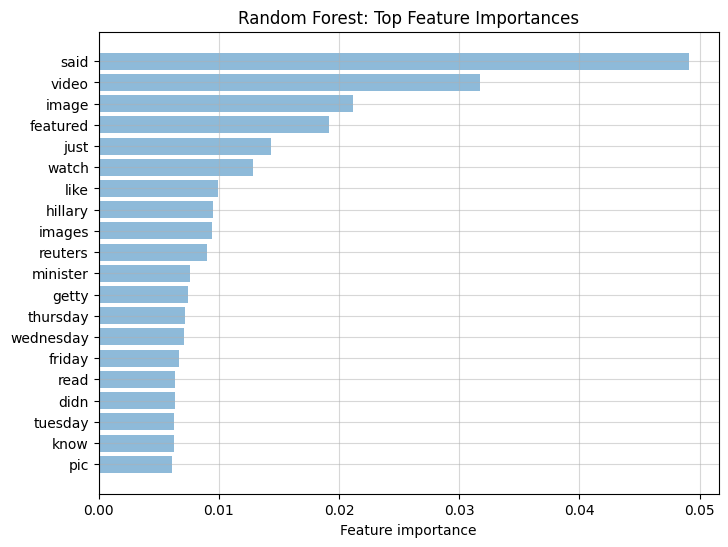

In [8]:
# EX.B.: Report a table (or plot) showing the top 20 most important terms to
# perform the prediction according to one of the trained models.

# Chart
rf_importance = pd.Series(rf_best.feature_importances_, index = feature_names).sort_values(ascending = False)
k = 20
imp_rf_top = rf_importance.head(k).sort_values(ascending = True)

plt.figure(figsize = (8,6))
plt.barh( imp_rf_top.index, imp_rf_top.values, alpha = 0.5)
plt.grid(alpha = 0.5)

plt.xlabel("Feature importance")
plt.title("Random Forest: Top Feature Importances")
plt.tight_layout()

# Table
imp_rf_table = (
    pd.DataFrame({
        "Term": imp_rf_top.index,
        "Importance": imp_rf_top.values
    })
    .sort_values(by = "Importance", ascending = False)  
    .reset_index(drop = True)                         
)

imp_rf_table.index = imp_rf_table.index + 1
imp_rf_table.index.name = "Ranking"

display(imp_rf_table)